In [ ]:
                        ############# Deep Neural Network in Jupyter Notebook ######################

In [1]:
########## 1. Installing and Importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
#import statsmodels.api as sm


In [2]:
################ 2. Loading the dataset
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [3]:
# Random seed for reproducibility purposes
np.random.seed(42)
tf.random.set_seed(42)

In [4]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [5]:
############# 3. Data Preparation

In [6]:
# Target variable, y
y = data['pH']

In [7]:
# Feature variables
X = data[['x_coord', 'y_coord', 'T', 'Depth']]

In [8]:
# Standardizing / Scaling the input features, very important for NN
scaler = StandardScaler() # # Initializing the scaler 
scaler.fit(X) # Fitting the scaler on X
# Scaling X
X = scaler.transform(X)

In [9]:
# Splitting the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [10]:
# Printing the training and testing feature shape
print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (917, 4)
Testing set size: (394, 4)


In [11]:
########## 4. Build the Deep Neural Network Architecture
def build_deep_neural_network(input_dim):
    model = Sequential([
        # Input Layer + Hidden Layer 1
        Dense(64, activation = 'relu', input_shape = (input_dim,)),
        BatchNormalization(),
        Dropout(0.28),
        
        # Hidden Layer 2
        Dense(32, activation = 'relu'),
        BatchNormalization(),
        Dropout(0.28),
        
        # Hidden Layer 3
        Dense(16, activation = 'relu'),
        
        # Outputting the Layer (1 continuous output for regression)
        Dense(1, activation = 'linear')
    ])
    
    model.compile(
        optimizer = tf.keras.optimizers.SGD(learning_rate = 0.005),
        loss='mse',
        metrics=['mae']
    )
    return model

model = build_deep_neural_network(X_train.shape[1])
model.summary()


C:\Users\Djimadoumngar\anaconda3\envs\NNetwork\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 192 (768.00 B)

In [28]:
############## 5. Training the Neural Network

In [12]:
# a. Implementing Early Stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=15, 
    restore_best_weights = True
)

# b. Training the model
history = model.fit(
    X_train, y_train,
    validation_split = 0.3,
    epochs = 150,
    batch_size = 16,
    callbacks = [early_stop],
    verbose = 1
)


Epoch 1/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 12.0746 - mae: 2.7139 - val_loss: 8.6868 - val_mae: 2.8418
Epoch 2/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 2.6283 - mae: 1.2826 - val_loss: 4.7387 - val_mae: 2.0256
Epoch 3/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.9711 - mae: 1.1210 - val_loss: 2.1557 - val_mae: 1.2448
Epoch 4/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.4381 - mae: 0.9187 - val_loss: 1.3545 - val_mae: 0.8875
Epoch 5/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.4919 - mae: 0.9459 - val_loss: 0.9976 - val_mae: 0.7543
Epoch 6/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.1018 - mae: 0.8133 - val_loss: 0.9084 - val_mae: 0.7330
Epoch 7/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.1191 - mae: 0.8312 - val_loss: 0.7896 - val_mae: 0.6860
Epoch 8/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0206 - mae: 0.8066 - val_loss: 0.7182 - val_mae: 0.6469
Epoch 9/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - lo

In [30]:
############## 6. Model Evaluation 

In [13]:
### On the training dataset
###### Predicting using the training dataset
y_pred_train = model.predict(X_train).flatten()

# Printing the metrics
mse = mean_squared_error(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)

print(' Training Data Metrics ')
print(f'- Mean Absolute Error (MAE): {mae:.2f}')
print(f'- Mean Squared Error (MSE):  {mse:.2f}')
print(f'- R² Score:                  {r2:.2f}')


29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
 Training Data Metrics 
- Mean Absolute Error (MAE): 0.40
- Mean Squared Error (MSE):  0.33
- R² Score:                  0.19


In [14]:
####### Using the testing dataset
####### Predicting on Test Data
y_pred_test = model.predict(X_test).flatten()

# Print the Metrics
mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)

print(' Testing Data Metrics ')
print(f' - Mean Absolute Error (MAE): {mae:.2f}')
print(f' - Mean Squared Error (MSE):  {mse:.2f}')
print(f' - R² Score:                  {r2:.2f}')


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
 Testing Data Metrics 
 - Mean Absolute Error (MAE): 0.39
 - Mean Squared Error (MSE):  0.28
 - R² Score:                  0.12


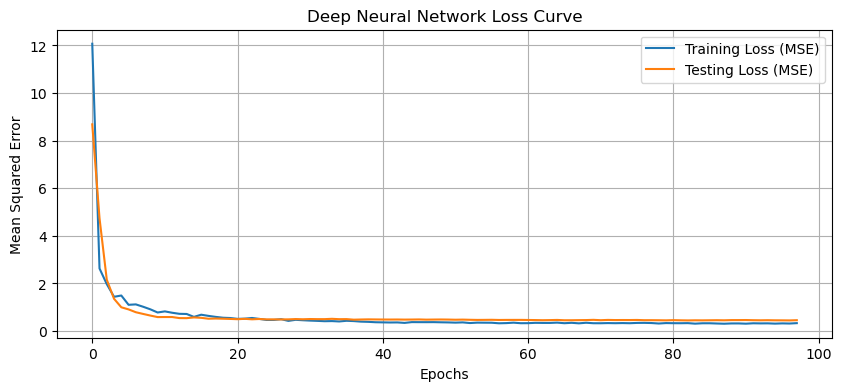

In [15]:
### Ploting the Training and Testing Loss Curves
plt.figure(figsize = (10, 4))
plt.plot(history.history['loss'], label = 'Training Loss (MSE)')
plt.plot(history.history['val_loss'], label = 'Testing Loss (MSE)')
plt.title('Deep Neural Network Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()


In [34]:
################## Ploting Predicted vs. Actual pH Data

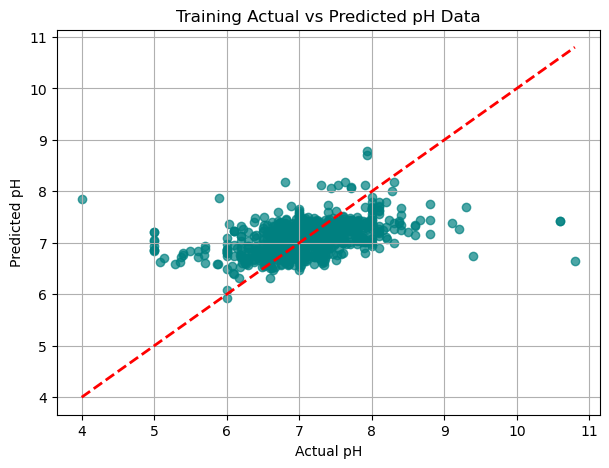

In [16]:
# On the training dataset

plt.figure(figsize = (7, 5))
plt.scatter(y_train, y_pred_train, alpha = 0.7, color = 'teal')
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw = 2)
plt.xlabel('Actual pH')
plt.ylabel('Predicted pH')
plt.title('Training Actual vs Predicted pH Data')
plt.grid(True)
plt.show()


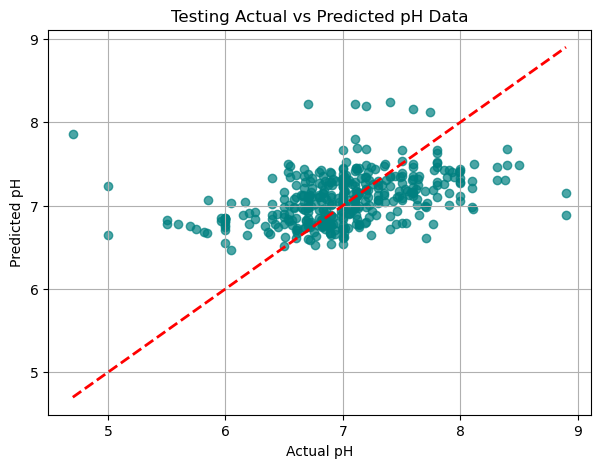

In [17]:
################## Ploting Predicted vs. Actual pH Data
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_test, alpha=0.7, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual pH')
plt.ylabel('Predicted pH')
plt.title('Testing Actual vs Predicted pH Data')
plt.grid(True)
plt.show()
